# Do tax signals predict stock returns? A walkthrough

This notebook tells the whole project in about a minute of running time. It only reads the finished files in `data/`, `results/` and `models/`, so nothing is downloaded. The scripts that built those files are described in the [README](../README.md).

**Question:** using a company's tax data, tax abatements and filing behavior, can we predict whether its stock beats the S&P 500 over the next 12 months?

- One row = one company in one fiscal year (a *company-year*).
- Target = `beat_sp500`: 1 if the stock's return over the 12 months after its 10-K was filed beat the S&P 500.
- Models = Logistic regression, Random Forest, AdaBoost, XGBoost.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # so we can import the project's own code
DATA, RESULTS, MODELS = ROOT / "data", ROOT / "results", ROOT / "models"

def load(name):
    """Read data/<name>.csv, or the gzipped copy used on GitHub."""
    path = DATA / f"{name}.csv"
    return pd.read_csv(path if path.exists() else DATA / f"{name}.csv.gz")

pd.set_option("display.precision", 3)

## 1. The data

Five sources were pulled and joined on company (`cik`) and fiscal year:

| Step | What | Source |
|---|---|---|
| 1 | Tax figures: effective tax rate, cash taxes, deferred taxes | SEC EDGAR XBRL API |
| 2 | Late-filing notices (NT 10-K / NT 10-Q), 10-K filing dates | SEC EDGAR filing index |
| 3 | 12-month stock return vs the S&P 500 (the target) | Yahoo Finance |
| 4 | Tax abatements | New York State IDA data |
| 5 | Controls: size, industry, exchange, profitability, last year's return... | SEC EDGAR |

The result is one modeling table. The split is by **time**, never random: the models learn from fiscal 2012-2020 and are tested on 2021-2024, so they never see the future.

In [2]:
df = load("modeling_table")
print(f"{len(df):,} company-years, {df.cik.nunique():,} companies, {df.shape[1]} columns")
df.groupby("split").agg(company_years=("cik", "size"),
                        first_year=("fiscal_year", "min"),
                        last_year=("fiscal_year", "max"),
                        share_beat_sp500=("beat_sp500", "mean"))

43,668 company-years, 4,522 companies, 60 columns


,company_years,first_year,last_year,share_beat_sp500
split,,,,
test,17008,2021,2024,0.339
train,26660,2012,2020,0.403


Fewer than half of stocks beat the S&P 500 in most years. That's normal: the index is weighted toward its biggest winners, so the typical stock trails it. In 2021-2024 a handful of mega-caps carried the index, and the share drops further.

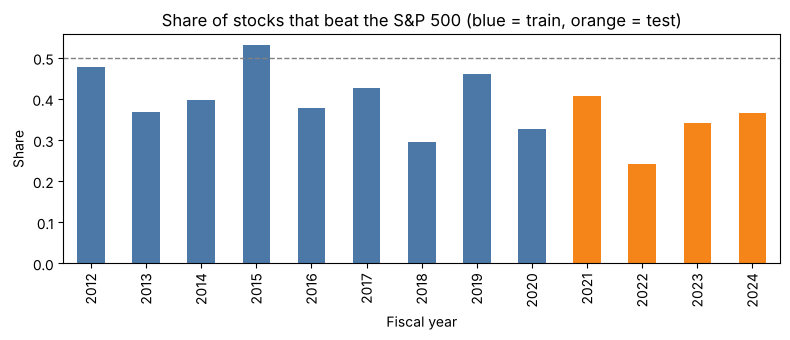

In [3]:
by_year = df.groupby("fiscal_year").beat_sp500.mean()
ax = by_year.plot.bar(color=["#4C78A8" if y <= 2020 else "#F58518" for y in by_year.index], figsize=(8, 3.5))
ax.axhline(0.5, color="grey", lw=1, ls="--")
ax.set(title="Share of stocks that beat the S&P 500 (blue = train, orange = test)",
       xlabel="Fiscal year", ylabel="Share")
plt.tight_layout(); plt.show()

### A few of the features

- **ETR** (effective tax rate) = tax expense / pretax income. It is blank when the company had a loss, because a tax rate on a loss means nothing. Loss years are kept and flagged (`pretax_loss`).
- **Cash vs book tax** (`cash_to_book_tax`) = taxes actually paid / tax expense.
- **NT 10-K** = the company filed a notice that its annual report would be late.
- **Abatements** = tax breaks from New York IDAs. Very rare: the data only covers New York.

In [4]:
pd.Series({
    "ETR blank (loss or tiny profit)": df.etr.isna().mean(),
    "Pretax loss": df.pretax_loss.mean(),
    "Late 10-K (NT 10-K)": df.nt_10k.mean(),
    "Got a NY tax abatement": df.abate_any.mean(),
}, name="share of company-years").to_frame()

,share of company-years
ETR blank (loss or tiny profit),0.500
Pretax loss,0.313
Late 10-K (NT 10-K),0.078
Got a NY tax abatement,0.008


## 2. Key finding: slow 10-K filers lose money

Every public company has an SEC deadline to file its 10-K (60, 75 or 90 days after year-end, depending on size). Companies that file late are far more likely to be losing money, and their stocks do worse. A quick check straight from the table:

In [5]:
quick = (df.assign(late_10k=df.nt_10k.map({0: "Filed on time", 1: "Filed an NT 10-K (late)"}))
           .groupby("late_10k")
           .agg(company_years=("cik", "size"),
                share_with_loss=("pretax_loss", "mean"),
                median_return_vs_sp500=("excess_ret_12m", "median"),
                share_beat_sp500=("beat_sp500", "mean")))
quick

,company_years,share_with_loss,median_return_vs_sp500,share_beat_sp500
late_10k,,,,
Filed an NT 10-K (late),3386,0.564,-0.369,0.277
Filed on time,40282,0.292,-0.102,0.386


The full test (`filing_delay_test.py`) measures each company's delay against its own deadline and holds size, industry and year constant:

In [6]:
groups = pd.read_csv(RESULTS / "filing_delay_groups.csv")
groups[["delay_group", "company_years", "share_loss_now", "share_loss_next_year",
        "median_excess_return", "share_beat_sp500"]]

,delay_group,company_years,share_loss_now,share_loss_next_year,median_excess_return,share_beat_sp500
0,Early (8+ days before deadline),15426,0.303,0.301,-0.081,0.403
1,Last week before deadline,20635,0.317,0.324,-0.103,0.386
2,"Late, within NT extension",3498,0.666,0.672,-0.333,0.277
3,Very late (past extension),1465,0.742,0.745,-0.356,0.310


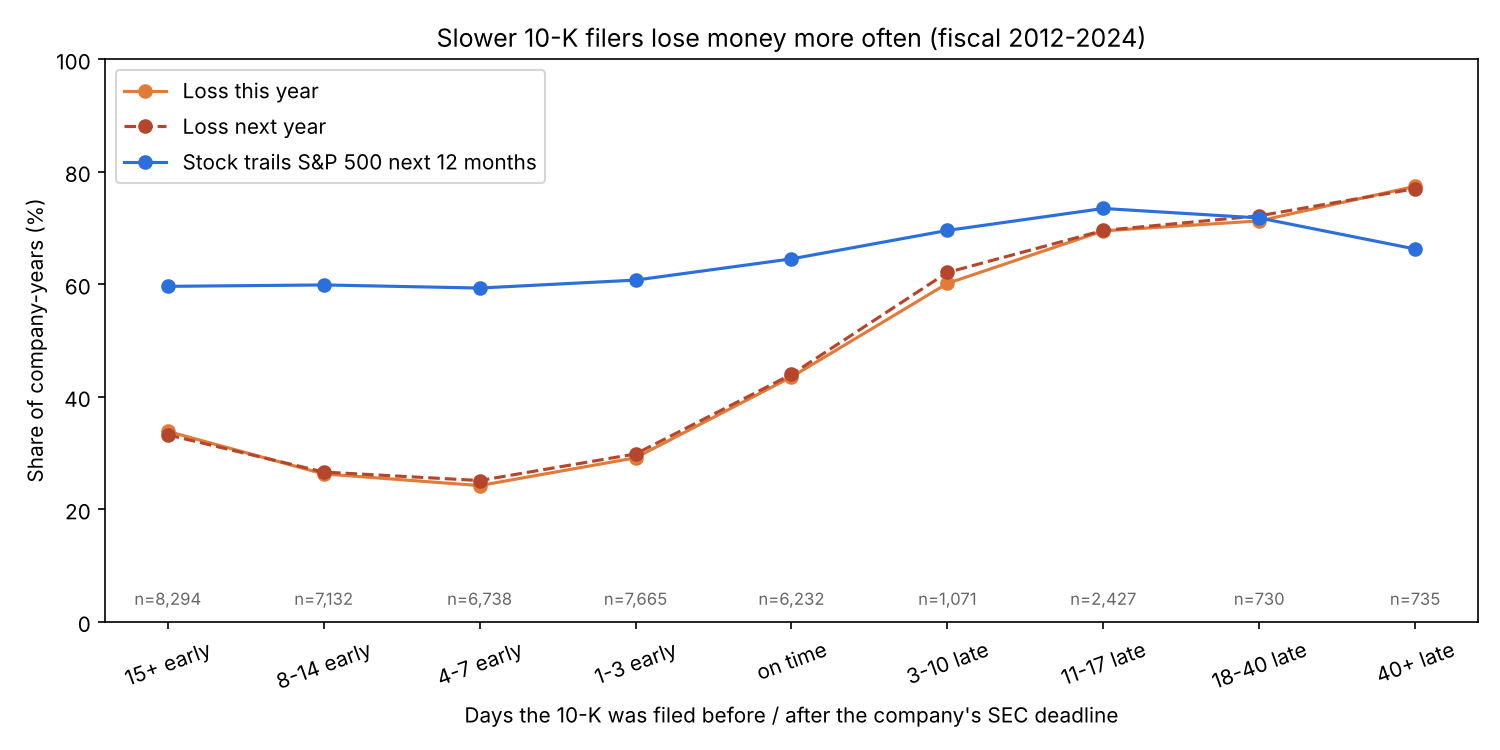

In [7]:
display(Image(RESULTS / "filing_delay.png", width=900))

- Late filers (within the NT extension) lost money **67%** of the time, vs **30%** for early filers; very late filers **74%**.
- It is not just small companies: among the largest fifth, **39%** of very late filers lost money vs **9%** of early filers.
- Filing past the deadline raises the odds of a loss **next year by 48%**, even holding this year's loss and ROA constant, and goes with a 12-month return **9.6 points lower** vs the S&P 500.

**Correlation, not cause:** late filing is usually a symptom of accounting or business trouble, not its source.

## 3. The four models

Settings were tuned on 2018-2020, then each model was refit on 2012-2020 and scored **once** on 2021-2024. AUC measures how well a model ranks winners above losers: 0.50 is a coin flip, and for stock returns 0.55-0.60 counts as good. Each model was also trained on the controls only (size, profitability, industry...) to see what the tax and filing signals add.

In [8]:
metrics = pd.read_csv(RESULTS / "model_metrics.csv")
metrics[metrics.features == "all"][["model_name", "auc", "auc_low", "auc_high",
                                   "auc_gain_vs_controls", "top10pct_beat_rate"]] \
    .rename(columns={"auc": "test_auc", "auc_gain_vs_controls": "gain_vs_controls_only",
                     "top10pct_beat_rate": "top_10pct_beat_rate"})

,model_name,test_auc,auc_low,auc_high,gain_vs_controls_only,top_10pct_beat_rate
0,Logit,0.544,0.535,0.553,4.200e-03,0.369
1,Random Forest,0.564,0.555,0.572,6.300e-03,0.360
2,AdaBoost,0.544,0.536,0.553,6.000e-04,0.345
3,XGBoost,0.542,0.533,0.551,-3.000e-04,0.342


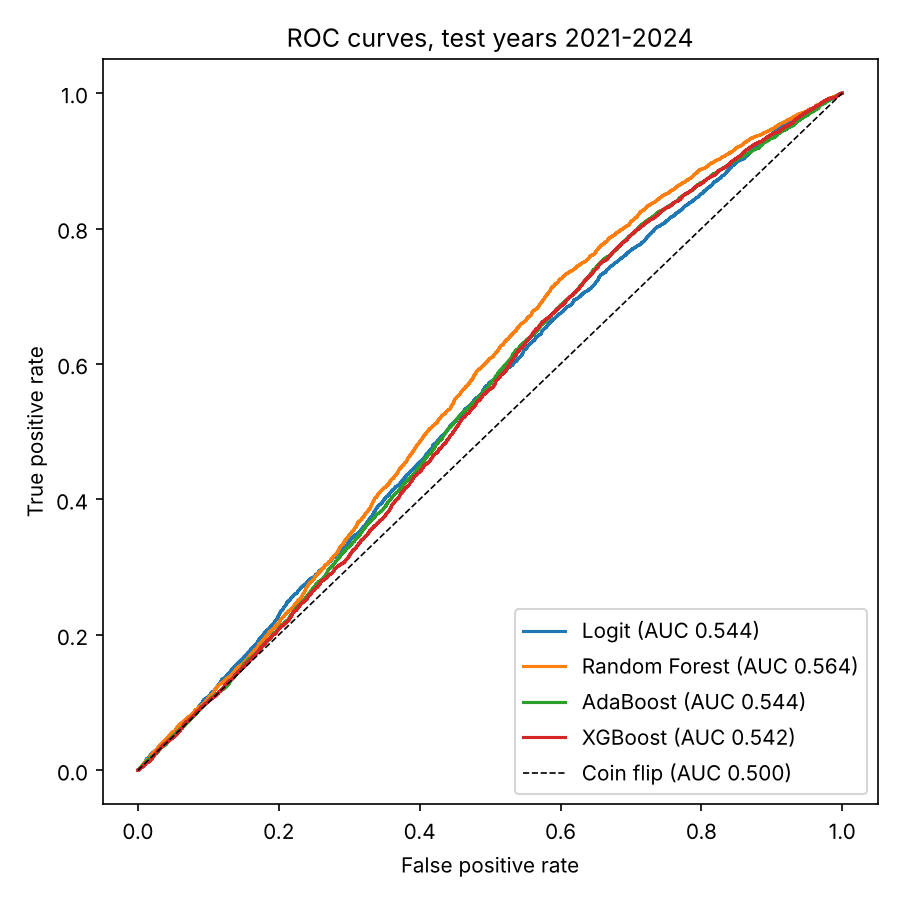

In [9]:
display(Image(RESULTS / "roc_curves.png", width=700))

Random Forest is best (test AUC 0.564). Unlike the credit card churn capstone, XGBoost did not win: with this little signal, its extra flexibility mostly fits noise. The honest headline is that a controls-only model does almost as well.

## 4. Which signals matter

Permutation importance shuffles one feature (or a whole group) in the test years and measures how much the AUC drops. A bigger drop means the model relies on it more.

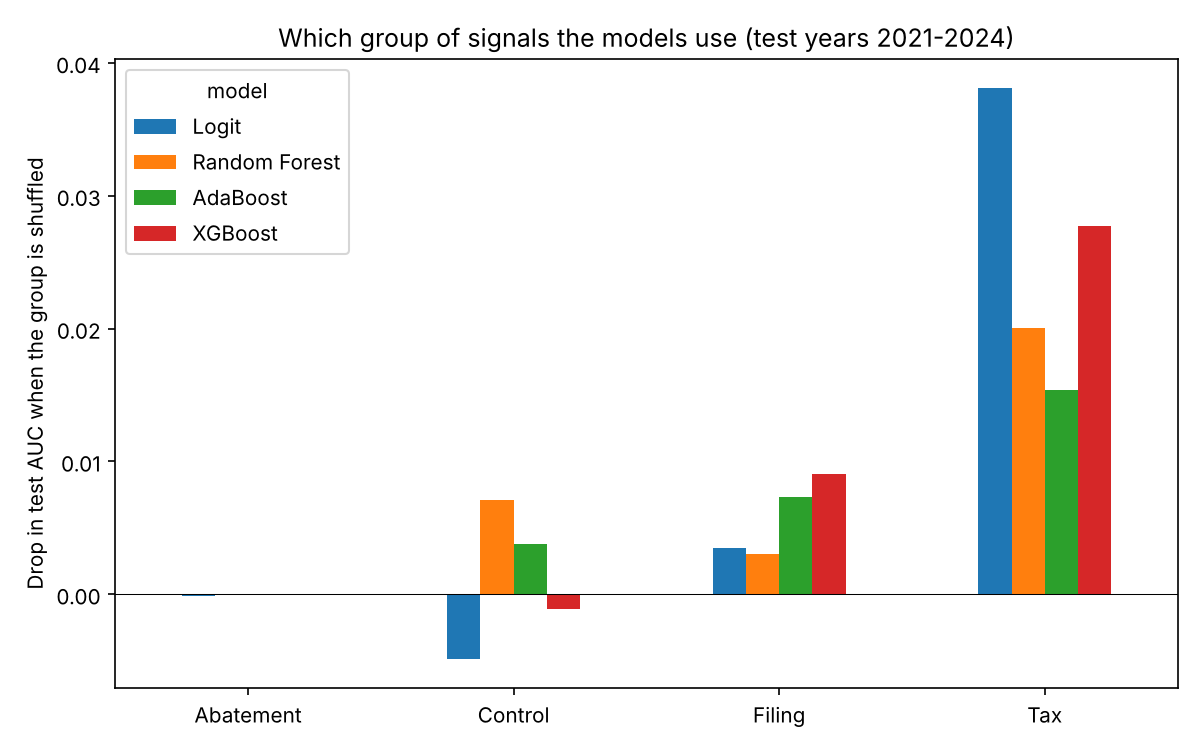

In [10]:
display(Image(RESULTS / "importance_by_group.png", width=700))

In [11]:
imp = pd.read_csv(RESULTS / "permutation_importance.csv")
(imp[(imp.model == "rf") & (imp.level == "feature")]
    .nlargest(10, "auc_drop")[["feature", "category", "auc_drop"]]
    .reset_index(drop=True))

,feature,category,auc_drop
0,log_total_assets,Control,3.370e-03
1,roa,Control,2.820e-03
2,cash_to_book_tax,Tax,2.400e-03
3,cash_etr,Tax,1.380e-03
4,filing_lag_days,Filing,1.270e-03
5,etr_change,Tax,1.230e-03
6,size_quintile,Control,9.700e-04
7,tenk_filing_lag_days,Filing,7.700e-04
8,exchange,Control,4.300e-04
9,net_deferred_tax_to_assets,Tax,3.700e-04


- **Tax signals are the group the models use most**, especially cash taxes paid vs tax expense, change in ETR and cash ETR.
- **Filing speed** matters more than the late-filing notices themselves.
- **Abatements add nothing**, but with only 348 company-years (New York only) that is inconclusive, not proof they don't matter.

## 5. Portfolio test

Each test year, rank stocks by Random Forest's probability and hold the top or bottom 10% for 12 months. This is a light version: no trading costs, and no Sharpe ratio or alpha.

In [12]:
port = pd.read_csv(RESULTS / "portfolio_summary.csv")
port[port.model.fillna("None").isin(["Random Forest", "None"])][
    ["portfolio", "avg_return", "avg_sp500_return", "avg_excess_return", "years_beating_sp500"]]

,portfolio,avg_return,avg_sp500_return,avg_excess_return,years_beating_sp500
0,All stocks,0.042,0.145,-0.103,0
4,Top 10%,0.067,0.146,-0.079,0
5,Top 20%,0.074,0.145,-0.071,0
6,Bottom 10%,-0.153,0.147,-0.300,0


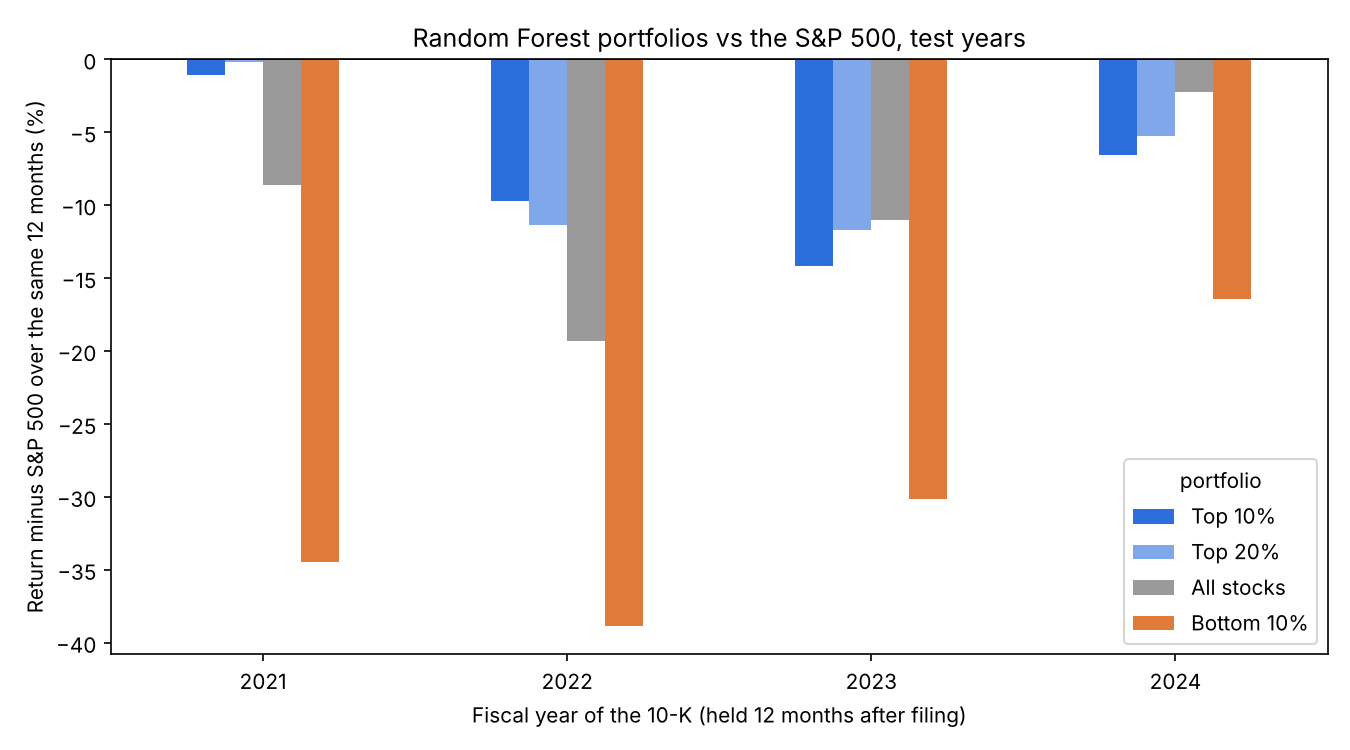

In [13]:
display(Image(RESULTS / "portfolio_returns.png", width=800))

The top picks never beat the S&P 500 in 2021-2024, but the bottom 10% trailed it by 30% a year. **The model is much better at spotting losers than winners.**

## 6. Use a saved model

The four trained models are saved in `models/`. Here the Random Forest scores the 2024 companies and lists the ones it rates least likely to beat the S&P 500.

In [14]:
from save_models import prepare

bundle = joblib.load(MODELS / "rf.pkl")
test = df[df.split == "test"].copy()
test["prob_beat"] = bundle["model"].predict_proba(prepare(test, bundle))[:, 1]

latest = test[test.fiscal_year == test.fiscal_year.max()]
latest.nsmallest(10, "prob_beat")[["name", "symbol", "fiscal_year", "prob_beat",
                                   "nt_10k", "pretax_loss", "excess_ret_12m"]]

,name,symbol,fiscal_year,prob_beat,nt_10k,pretax_loss,excess_ret_12m
40406,"Ankam, Inc.",ANKM,2024,0.317,1,1,9.775e-04
43262,"Cyber Enviro-Tech, Inc.",CETI,2024,0.320,1,1,-1.149e+00
29580,"BASANITE, INC.",BASA,2024,0.320,0,0,-6.014e-01
42354,Glidelogic Corp.,GDLG,2024,0.322,0,0,-8.068e-01
28423,RARE ELEMENT RESOURCES LTD,REEMF,2024,0.325,0,1,8.861e-02
43379,"Unusual Machines, Inc.",UMAC,2024,0.327,0,1,6.092e-01
32368,"Nexalin Technology, Inc.",NXL,2024,0.328,0,1,-1.024e+00
36905,"Myseum.AI, Inc.",MYSE,2024,0.328,0,1,-7.049e-01
19568,"SKINVISIBLE, INC.",SKVI,2024,0.329,1,0,-5.169e-01
31204,SKYTECH ORION GLOBAL CORP.,SKTG,2024,0.333,0,0,1.667e+00


## 7. Conclusion and limitations

**The 10-K filing date is the strongest signal in the project.** Companies that file late are about twice as likely to be losing money, more likely to lose money next year, and their stocks trail the market. It holds for large companies too. It is a correlation, not a cause.

The broader prediction model is modest: tax signals are what the models use most, but they overlap with size and profitability, and they were not enough to beat the S&P 500 in 2021-2024. Tax and filing data work best for **flagging stocks likely to do badly**.

Limitations:
- **Survivorship bias:** delisted companies are mostly missing, which probably makes late filers look *better* than they were.
- Sector, exchange and HQ are today's values applied to past years.
- Abatements cover New York only, from 2018.
- The test window is four years, dominated by a few mega-caps.
- No trading costs in the portfolio test.